# Regularización con datos de la NBA en PyTorch

Predeciremos si un jugador continúa al menos cinco años en la NBA a partir de sus estadísticas de temporada iniciales. Compararemos una red base con L1, L2, *dropout* y detención temprana.

## Entorno y objetivo

Ejecuta este notebook con el kernel **IPD434**. El código usa CUDA si PyTorch detecta una GPU y continúa en CPU si no está disponible. Los datos se leen desde `../data/nba.csv`.

Limitaremos el conjunto para que la comparación sea breve. La partición de prueba se mantiene separada hasta elegir el modelo con validación.

In [1]:
import copy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 2026
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('Dispositivo:', device)

PyTorch: 2.11.0+cu128
Dispositivo: cuda


## Preparar los datos de la NBA

Eliminamos filas incompletas y retiramos el nombre del jugador de las características. Separamos los datos antes de escalar para evitar filtrar información de validación o prueba.

In [2]:
DATA_PATH = Path('../data/nba.csv')
df = pd.read_csv(DATA_PATH, index_col='Name')
n_before = len(df)
df = df.dropna().copy()
X = df.drop(columns='TARGET_5Yrs').astype(np.float32)
y = df['TARGET_5Yrs'].astype(np.int64)
print('Filas leídas:', n_before, '| filas completas:', len(df))
print('Características:', X.shape[1])
print('Clases:', y.value_counts().sort_index().to_dict())

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.20, random_state=42,
    stratify=y_train_full
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

def make_loader(features, labels, batch_size=64, shuffle=False, seed=SEED):
    x_tensor = torch.tensor(features, dtype=torch.float32)
    y_tensor = torch.tensor(labels.to_numpy(), dtype=torch.float32)
    generator = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(
        TensorDataset(x_tensor, y_tensor), batch_size=batch_size,
        shuffle=shuffle, generator=generator, num_workers=0
    )

train_loader = make_loader(X_train, y_train, shuffle=True)
train_eval_loader = make_loader(X_train, y_train)
val_loader = make_loader(X_val, y_val)
test_loader = make_loader(X_test, y_test)
print('Particiones:', len(X_train), len(X_val), len(X_test))

Filas leídas: 1340 | filas completas: 1329
Características: 19
Clases: {0: 503, 1: 826}
Particiones: 850 213 266


## Estrategias que compararemos

- **L1:** penaliza la suma de valores absolutos de los pesos y puede llevar algunos a cero.
- **L2:** penaliza la suma de cuadrados y reduce la magnitud de los pesos.
- **Dropout:** anula activaciones aleatorias mientras se entrena.
- **Detención temprana:** detiene el ajuste cuando la pérdida de validación deja de mejorar y restaura la mejor época.

Comparamos la red base con época fija frente a la misma red con detención temprana. Las variantes L1, L2 y *dropout* usan la misma cantidad máxima de épocas.

In [3]:
class NBAClassifier(nn.Module):
    def __init__(self, n_features, dropout=0.0):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_features, 19),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(19, 10),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(10, 1),
        )

    def forward(self, features):
        return self.layers(features).squeeze(1)

criterion = nn.BCEWithLogitsLoss()
MAX_EPOCHS = 100
PATIENCE = 5

def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_labels, all_predictions = [], []
    with torch.no_grad():
        for features, labels in loader:
            features, labels = features.to(device), labels.to(device)
            logits = model(features)
            loss = criterion(logits, labels)
            total_loss += loss.item() * labels.size(0)
            predictions = (torch.sigmoid(logits) >= 0.5).long()
            correct += (predictions == labels.long()).sum().item()
            all_labels.append(labels.cpu().numpy())
            all_predictions.append(predictions.cpu().numpy())
            total += labels.size(0)
    balanced = balanced_accuracy_score(
        np.concatenate(all_labels), np.concatenate(all_predictions)
    )
    return total_loss / total, correct / total, balanced

def regularization_penalty(model, kind, strength):
    weights = [p for name, p in model.named_parameters() if name.endswith('weight')]
    if kind == 'l1':
        return strength * sum(p.abs().sum() for p in weights)
    if kind == 'l2':
        return strength * sum(p.square().sum() for p in weights)
    return torch.zeros((), device=device)

def fit_model(name, reg=None, strength=0.0, dropout=0.0, early_stopping=False):
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    model = NBAClassifier(X_train.shape[1], dropout=dropout).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loader = make_loader(X_train, y_train, batch_size=64, shuffle=True, seed=SEED)
    history = {
        'train_loss': [], 'val_loss': [],
        'train_accuracy': [], 'val_accuracy': [],
        'train_balanced_accuracy': [], 'val_balanced_accuracy': [],
    }
    best_loss = float('inf')
    best_state = copy.deepcopy(model.state_dict())
    best_epoch, waiting = 0, 0

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        for features, labels in loader:
            features, labels = features.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(features)
            data_loss = criterion(logits, labels)
            loss = data_loss + regularization_penalty(model, reg, strength)
            loss.backward()
            optimizer.step()

        train_loss, train_accuracy, train_balanced = evaluate(model, train_eval_loader)
        val_loss, val_accuracy, val_balanced = evaluate(model, val_loader)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_accuracy'].append(train_accuracy)
        history['val_accuracy'].append(val_accuracy)
        history['train_balanced_accuracy'].append(train_balanced)
        history['val_balanced_accuracy'].append(val_balanced)
        if epoch == 1 or epoch % 10 == 0:
            print(
                f'{name} | época {epoch:03d} | '
                f'train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | '
                f'val_acc={val_accuracy:.3f}'
            )

        if val_loss < best_loss - 1e-4:
            best_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            waiting = 0
        else:
            waiting += 1
            if early_stopping and waiting >= PATIENCE:
                print('Detención temprana.')
                break

    if early_stopping:
        model.load_state_dict(best_state)
    else:
        best_epoch = len(history['val_loss'])
        best_loss = history['val_loss'][-1]
    return model, history, best_epoch, best_loss

## Sobreajuste de la red base

Primero entrenamos la red sin L1, L2 ni *dropout* durante 300 épocas. Este experimento separado muestra qué ocurre cuando el ajuste continúa después de que la validación deja de mejorar. Guardamos también los pesos de la época 100 para la comparación posterior.

In [4]:
OVERFIT_EPOCHS = 300
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
base_overfit = NBAClassifier(X_train.shape[1]).to(device)
base_optimizer = torch.optim.Adam(base_overfit.parameters(), lr=1e-3)
base_loader = make_loader(X_train, y_train, batch_size=64, shuffle=True, seed=SEED)
base_history = {
    'train_loss': [], 'val_loss': [],
    'train_accuracy': [], 'val_accuracy': [],
    'train_balanced_accuracy': [], 'val_balanced_accuracy': [],
}
base_state_100 = None

for epoch in range(1, OVERFIT_EPOCHS + 1):
    base_overfit.train()
    for features, labels in base_loader:
        features, labels = features.to(device), labels.to(device)
        base_optimizer.zero_grad(set_to_none=True)
        loss = criterion(base_overfit(features), labels)
        loss.backward()
        base_optimizer.step()

    train_metrics = evaluate(base_overfit, train_eval_loader)
    val_metrics = evaluate(base_overfit, val_loader)
    base_history['train_loss'].append(train_metrics[0])
    base_history['train_accuracy'].append(train_metrics[1])
    base_history['train_balanced_accuracy'].append(train_metrics[2])
    base_history['val_loss'].append(val_metrics[0])
    base_history['val_accuracy'].append(val_metrics[1])
    base_history['val_balanced_accuracy'].append(val_metrics[2])
    if epoch == 100:
        base_state_100 = copy.deepcopy(base_overfit.state_dict())
    if epoch == 1 or epoch % 50 == 0:
        print(f'Época {epoch:03d} | train_BCE={train_metrics[0]:.4f} | val_BCE={val_metrics[0]:.4f}')

assert base_state_100 is not None

Época 001 | train_BCE=0.6678 | val_BCE=0.6714
Época 050 | train_BCE=0.5379 | val_BCE=0.5556
Época 100 | train_BCE=0.5113 | val_BCE=0.5577
Época 150 | train_BCE=0.4784 | val_BCE=0.5701
Época 200 | train_BCE=0.4444 | val_BCE=0.5907
Época 250 | train_BCE=0.4154 | val_BCE=0.6284
Época 300 | train_BCE=0.3909 | val_BCE=0.6691


## Sobreajuste en la red base

Antes de comparar regularizadores, entrenamos esta red sin regularización durante 300 épocas. Si entrenamiento sigue bajando mientras validación sube, hay sobreajuste.

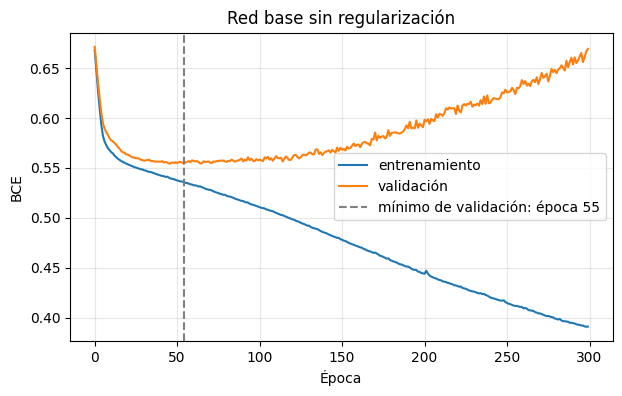

In [5]:
best_demo_epoch = int(np.argmin(base_history['val_loss'])) + 1
plt.figure(figsize=(7, 4))
plt.plot(base_history['train_loss'], label='entrenamiento')
plt.plot(base_history['val_loss'], label='validación')
plt.axvline(best_demo_epoch - 1, color='gray', linestyle='--', label=f'mínimo de validación: época {best_demo_epoch}')
plt.xlabel('Época')
plt.ylabel('BCE')
plt.title('Red base sin regularización')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Entrenar las configuraciones

La red conserva las capas ocultas de 19 y 10 unidades del ejemplo original. La salida es un logit y `BCEWithLogitsLoss` calcula la pérdida binaria.

El gráfico anterior entrena la red base sin regularización durante 300 épocas. La tabla compara sus primeros 100 pasos con L1, L2, *dropout* y detención temprana, usando la misma arquitectura y partición.

In [6]:
base_comparison_model = NBAClassifier(X_train.shape[1]).to(device)
base_comparison_model.load_state_dict(base_state_100)
models = {'Base, 100 épocas': base_comparison_model}
histories = {
    'Base, 100 épocas': {key: values[:MAX_EPOCHS] for key, values in base_history.items()}
}
base_index = MAX_EPOCHS - 1
rows = [{
    'configuración': 'Base, 100 épocas',
    'mejor época': MAX_EPOCHS,
    'pérdida entrenamiento': base_history['train_loss'][base_index],
    'pérdida validación': base_history['val_loss'][base_index],
    'exactitud entrenamiento': base_history['train_accuracy'][base_index],
    'exactitud validación': base_history['val_accuracy'][base_index],
    'exactitud balanceada': base_history['val_balanced_accuracy'][base_index],
}]

configurations = [
    ('Detención temprana', None, 0.0, 0.0, True),
    ('L1', 'l1', 1e-3, 0.0, False),
    ('L2', 'l2', 0.0, 1e-2, False),
    ('Dropout', None, 0.0, 0.3, False),
]
for name, reg, strength, dropout, early_stopping in configurations:
    model, history, best_epoch, best_val_loss = fit_model(
        name, reg=reg, strength=strength, dropout=dropout, early_stopping=early_stopping
    )
    models[name] = model
    histories[name] = history
    rows.append({
        'configuración': name,
        'mejor época': best_epoch,
        'pérdida entrenamiento': history['train_loss'][best_epoch - 1],
        'pérdida validación': best_val_loss,
        'exactitud entrenamiento': history['train_accuracy'][best_epoch - 1],
        'exactitud validación': history['val_accuracy'][best_epoch - 1],
        'exactitud balanceada': history['val_balanced_accuracy'][best_epoch - 1],
    })

summary = pd.DataFrame(rows).sort_values('pérdida validación')
display(summary.reset_index(drop=True))

Detención temprana | época 001 | train_loss=0.6678 | val_loss=0.6714 | val_acc=0.662
Detención temprana | época 010 | train_loss=0.5677 | val_loss=0.5798 | val_acc=0.704
Detención temprana | época 020 | train_loss=0.5543 | val_loss=0.5636 | val_acc=0.714
Detención temprana | época 030 | train_loss=0.5484 | val_loss=0.5576 | val_acc=0.718
Detención temprana | época 040 | train_loss=0.5428 | val_loss=0.5562 | val_acc=0.728
Detención temprana | época 050 | train_loss=0.5379 | val_loss=0.5556 | val_acc=0.723
Detención temprana.
L1 | época 001 | train_loss=0.6682 | val_loss=0.6716 | val_acc=0.657
L1 | época 010 | train_loss=0.5715 | val_loss=0.5802 | val_acc=0.709
L1 | época 020 | train_loss=0.5583 | val_loss=0.5597 | val_acc=0.714
L1 | época 030 | train_loss=0.5552 | val_loss=0.5537 | val_acc=0.714
L1 | época 040 | train_loss=0.5526 | val_loss=0.5523 | val_acc=0.714
L1 | época 050 | train_loss=0.5510 | val_loss=0.5506 | val_acc=0.718
L1 | época 060 | train_loss=0.5498 | val_loss=0.5503 | v

,configuración,mejor época,pérdida entrenamiento,pérdida validación,exactitud entrenamiento,exactitud validación,exactitud balanceada
0,L1,100,0.545258,0.548347,0.725882,0.708920,0.684063
1,Detención temprana,46,0.540133,0.554418,0.734118,0.727700,0.703984
2,Dropout,100,0.538830,0.555637,0.737647,0.718310,0.696409
3,"Base, 100 épocas",100,0.511255,0.557703,0.757647,0.713615,0.692621
4,L2,100,0.513707,0.560819,0.743529,0.732394,0.710157


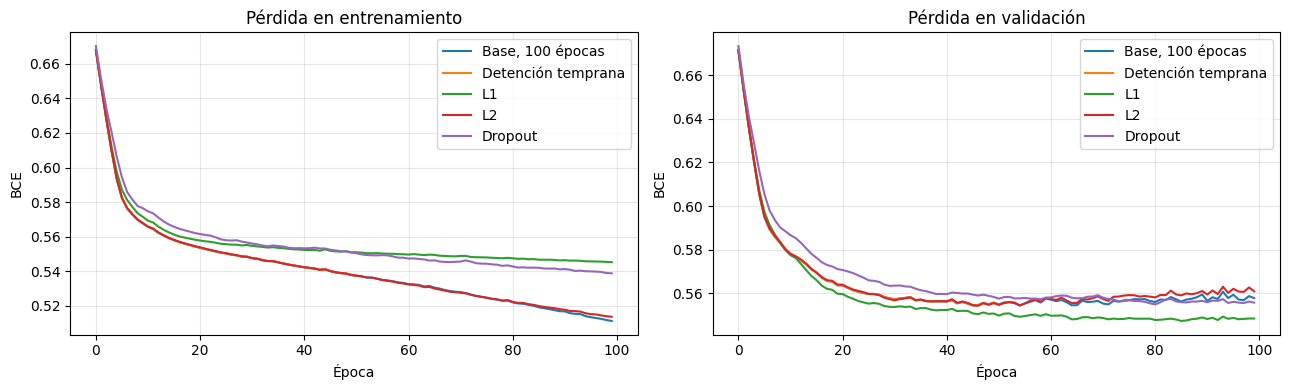

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, history in histories.items():
    axes[0].plot(history['train_loss'], label=name)
    axes[1].plot(history['val_loss'], label=name)
axes[0].set(title='Pérdida en entrenamiento', xlabel='Época', ylabel='BCE')
axes[1].set(title='Pérdida en validación', xlabel='Época', ylabel='BCE')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Evaluación final

Seleccionamos la configuración con menor pérdida de validación. Solo después consultamos la partición de prueba. Los resultados pueden variar con la inicialización, la partición y el hardware.

In [8]:
best_name = summary.iloc[0]['configuración']
test_loss, test_accuracy, test_balanced_accuracy = evaluate(models[best_name], test_loader)
print('Configuración seleccionada:', best_name)
print(f'Prueba | BCE={test_loss:.4f} | exactitud={test_accuracy:.3f} | exactitud balanceada={test_balanced_accuracy:.3f}')

Configuración seleccionada: L1
Prueba | BCE=0.5662 | exactitud=0.714 | exactitud balanceada=0.687
